In [25]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
from pyhdf.SD import SD, SDC
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.patches import Rectangle

ERROR 1: PROJ: proj_create_from_database: Open of /global/home/users/toireasamarie/.conda/envs/base_savio/share/proj failed


In [5]:
modis_file = '/global/scratch/users/toireasamarie/crop_data/MCD12C1.A2012001.051.2013178154403.hdf'

In [6]:
#reading the file using pyhdf
file = SD(modis_file, SDC.READ)

#printing all dataset names
datasets_dictionary = file.datasets()
for idx,sds in enumerate(datasets_dictionary.keys()):
    print (idx,sds)
    


0 Majority_Land_Cover_Type_1
1 Majority_Land_Cover_Type_1_Assessment
2 Land_Cover_Type_1_Percent
3 Majority_Land_Cover_Type_1_QC
4 Majority_Land_Cover_Type_2
5 Majority_Land_Cover_Type_2_Assessment
6 Land_Cover_Type_2_Percent
7 Majority_Land_Cover_Type_3
8 Majority_Land_Cover_Type_3_Assessment
9 Land_Cover_Type_3_Percent


In [7]:
#reading dataset
sds_obj = file.select('Majority_Land_Cover_Type_1') # select sds  
data = sds_obj.get()               # get sds data

# Check the dimensions
print(data.shape)

(3600, 7200)


In [8]:
rows,cols =data.shape 
df=pd.DataFrame({
    'row':np.repeat(np.arange(rows),cols),
    'col':np.tile(np.arange(cols),rows),
    'land_cover':data.flatten()
})

In [9]:
#don't have latitude or longitude, but can turn the shape into lat/lon coords becuase we know it's on a 0.05 degree grid 

n_lat, n_lon = data.shape

latitudes=np.linspace(90- 0.05/2, -90 + 0.05/2, n_lat)
longitudes=np.linspace(-180  +0.05/2, 180-0.05/2, n_lon)

lon_grid, lat_grid = np.meshgrid(longitudes, latitudes)

df=pd.DataFrame({
    'lat': lat_grid.flatten(),
    'lon': lon_grid.flatten(),
    'land_cover': data.flatten()
})

In [10]:
df

,lat,lon,land_cover
0,89.975,-179.975,0
1,89.975,-179.925,0
2,89.975,-179.875,0
3,89.975,-179.825,0
4,89.975,-179.775,0
...,...,...,...
25919995,-89.975,179.775,12
25919996,-89.975,179.825,12
25919997,-89.975,179.875,12
25919998,-89.975,179.925,12


In [13]:
df = df[df['land_cover'] >= 0]

lon_min, lon_max = -104, -80 
lat_min, lat_max = 36, 49 

df = df[(df['lon'] >= lon_min) &
(df['lon'] <= lon_max) &
(df['lat'] <= lat_max) &
(df['lat'] >= lat_min)
]

In [15]:
df['is_cropland'] = (df['land_cover'] == 12).astype(int)

In [16]:
df['grid_lat'] = ((df['lat'] - 0.05) // 0.1) * 0.1 + 0.05
df['grid_lon'] = ((df['lon'] - 0.05) // 0.1) * 0.1 + 0.05 

In [17]:
agg = df.groupby(['grid_lat','grid_lon'])['is_cropland'].agg(count='count', cropland_sum='sum').reset_index()

In [18]:
agg

,grid_lat,grid_lon,count,cropland_sum
0,35.95,-104.05,1,0
1,35.95,-103.95,2,0
2,35.95,-103.85,2,0
3,35.95,-103.75,2,0
4,35.95,-103.65,2,0
...,...,...,...,...
31566,48.95,-80.45,2,0
31567,48.95,-80.35,2,0
31568,48.95,-80.25,2,0
31569,48.95,-80.15,2,0


In [19]:
agg['cropland_fraction']=agg['cropland_sum']/agg['count']

In [20]:
agg

,grid_lat,grid_lon,count,cropland_sum,cropland_fraction
0,35.95,-104.05,1,0,0.0
1,35.95,-103.95,2,0,0.0
2,35.95,-103.85,2,0,0.0
3,35.95,-103.75,2,0,0.0
4,35.95,-103.65,2,0,0.0
...,...,...,...,...,...
31566,48.95,-80.45,2,0,0.0
31567,48.95,-80.35,2,0,0.0
31568,48.95,-80.25,2,0,0.0
31569,48.95,-80.15,2,0,0.0


In [22]:
cropland_grid= agg[agg['cropland_fraction'] >= 0.6].copy()
cropland_grid['is_majority_cropland']=True

In [23]:
cropland_mask = cropland_grid[['grid_lat', 'grid_lon', 'is_majority_cropland']]

In [24]:
cropland_mask

,grid_lat,grid_lon,is_majority_cropland
16,35.95,-102.45,True
17,35.95,-102.35,True
19,35.95,-102.15,True
20,35.95,-102.05,True
21,35.95,-101.95,True
...,...,...,...
31398,48.95,-97.25,True
31399,48.95,-97.15,True
31400,48.95,-97.05,True
31401,48.95,-96.95,True


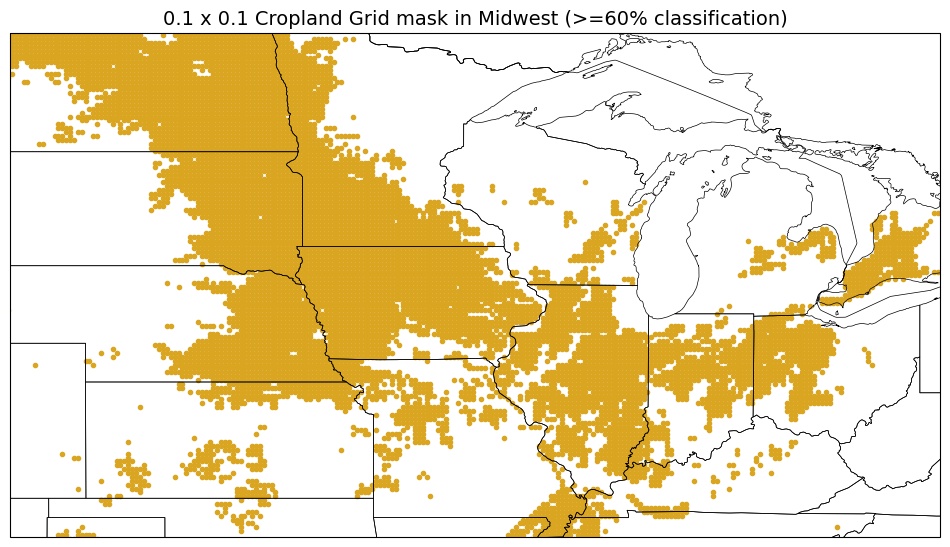

In [33]:
fig=plt.figure(figsize=(12,8))
ax=plt.axes(projection=ccrs.PlateCarree())

ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.add_feature(cfeature.COASTLINE, linewidth =0.5)
ax.add_feature(cfeature.STATES, linewidth =0.5)
ax.set_extent([-104, -80, 36, 49], crs=ccrs.PlateCarree())

sc=ax.scatter(cropland_mask['grid_lon'], cropland_mask['grid_lat'], c='goldenrod', s=9, transform=ccrs.PlateCarree(), label='Majority Cropland')

plt.title('0.1 x 0.1 Cropland Grid mask in Midwest (>=60% classification)', fontsize =14)
plt.legend
plt.show()

In [ ]:
#plotting with squares

In [35]:
grid=cropland_mask.pivot(index='grid_lat', columns='grid_lon', values='is_majority_cropland')
grid=grid.sort_index(ascending=True)

lon2d, lat2d = np.meshgrid(grid.columns.values, grid.index.values) 
mask2d = grid.values.astype(float)

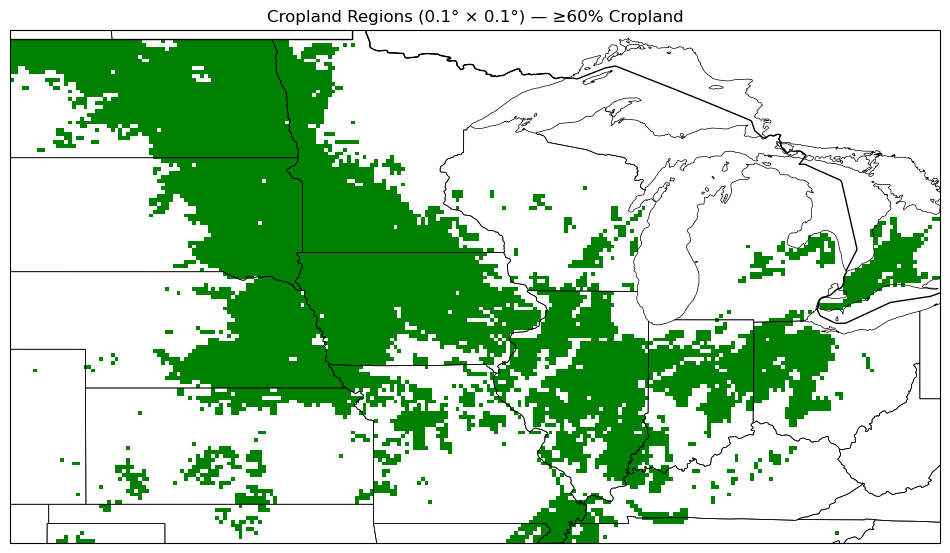

In [47]:
#Rectangle from matplotlib requires the bottom left corner which is why we subtract 0.05 from lat and lon 

fig = plt.figure(figsize=(12,8))
ax=plt.axes(projection=ccrs.PlateCarree())

ax.add_feature(cfeature.COASTLINE)
ax.add_feature(cfeature.BORDERS)
ax.add_feature(cfeature.STATES, linewidth = 0.5) 
ax.set_extent([-104, -80, 36, 49]) 

for _, row in cropland_mask.iterrows():
    rect = Rectangle(
        (row['grid_lon'] - 0.05, row['grid_lat'] - 0.05),  #bottom left corner
        0.1, 0.1, facecolor='green', linewidth=0.1,transform=ccrs.PlateCarree())
    ax.add_patch(rect)

plt.title("Cropland Regions (0.1° × 0.1°) — ≥60% Cropland")
plt.show()

In [48]:
cropland_mask

,grid_lat,grid_lon,is_majority_cropland
16,35.95,-102.45,True
17,35.95,-102.35,True
19,35.95,-102.15,True
20,35.95,-102.05,True
21,35.95,-101.95,True
...,...,...,...
31398,48.95,-97.25,True
31399,48.95,-97.15,True
31400,48.95,-97.05,True
31401,48.95,-96.95,True


In [49]:
output_file = '/global/scratch/users/toireasamarie/crop_data/0.1x0.1_cropland_mask'
cropland_mask.to_parquet(output_file, engine='pyarrow')